# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import base64

In [2]:
import ratinabox
from ratinabox.Environment import Environment
from ratinabox.Agent import Agent
from ratinabox.Neurons import FieldOfViewOVCs
# from ratinabox.Neurons import PlaceCells, GridCells #...

## aux funcs

In [3]:
import random
import string

def generate_random_string(n):
    """
    Generate a random string of length n.

    Parameters:
    n (int): The desired length of the string.

    Returns:
    str: A random string of length n.
    """
    if n <= 0:
        raise ValueError("Length 'n' must be a positive integer.")

    # Combine letters, digits, and punctuation
    characters = string.ascii_uppercase
    
    # Generate a random string of length n
    random_string = ''.join(random.choices(characters, k=n))

    return random_string


In [4]:
generate_random_string(8)

'EEQPDBQI'

In [5]:
def generate_all_positions_on_env(hole=None):

        # Define the range and step size
    step = 0.01  # Adjust the step size for granularity
    x_range = np.arange(0, 1 + step, step)
    y_range = np.arange(0, 1 + step, step)

    # Create a grid of (x, y) positions
    x, y = np.meshgrid(x_range, y_range)
    positions = np.column_stack([x.ravel(), y.ravel()])

    # Convert to a pandas DataFrame
    df_positions = pd.DataFrame(positions, columns=["X", "Y"])
    # df_positions['is_valid'] = [int(is_point_valid(pos, hole)) for pos in positions]
    df_positions['pos'] = [val for val in positions]

    return df_positions

In [6]:
def get_euclidean_distance(pos1, pos2):
    return np.sqrt((pos1[0] - pos2[0])**2 + ((pos1[1] - pos2[1])**2))
def apply_eucd_dist(x, obj=9):
    return get_euclidean_distance(x['pos'], x[f'obj_{obj}_pos'])

## Define EnV

In [7]:
Env = Environment(params={
    'aspect':1,
    # 'holes' : [[[0.4,0.2],[0.6,0.2],[0.6,0.8],[0.4,0.8]]],
    })

### Num of Cues

In [8]:
Env.has_holes

False

In [9]:
NUM_OF_CUES = 50

### RUN PARAMETERS

In [10]:
CUE_NAME_LEN = 4
MAX_NUMBER_OF_CUES = 5
# CONTEXT_LEN = MAX_NUMBER_OF_CUES*CUE_NAME_LEN
# CONTEXT_LEN

### gerando cues positions

In [11]:
CUES_LIST = []
num_test = 0
for i in range(NUM_OF_CUES):
    candidate_point = np.random.rand(), np.random.rand()
    CUES_LIST.append(candidate_point)
print(f'{NUM_OF_CUES} cues criadas com {num_test} candidatos')

50 cues criadas com 0 candidatos


### gerando all positions df

In [12]:
ap = generate_all_positions_on_env(hole=None)
ap.head()

,X,Y,pos
0,0.00,0.0,"[0.0, 0.0]"
1,0.01,0.0,"[0.01, 0.0]"
2,0.02,0.0,"[0.02, 0.0]"
3,0.03,0.0,"[0.03, 0.0]"
4,0.04,0.0,"[0.04, 0.0]"


### adicionando cues ao EnV

In [13]:
for point in CUES_LIST:
    Env.add_object(object=point,type=0)

In [14]:
len(Env.objects['objects']), NUM_OF_CUES

(50, 50)

In [15]:
objects_name_list = []
for i in range(NUM_OF_CUES):
    obj_name = generate_random_string(CUE_NAME_LEN)
    if obj_name in objects_name_list:
        obj_name = generate_random_string(CUE_NAME_LEN)
    objects_name_list.append(obj_name)

In [16]:
len(objects_name_list), len(set(objects_name_list))

(50, 50)

In [17]:
objects_name_list[:3]

['ZSBY', 'WKIR', 'NNRD']

In [18]:
Env.objects['object_names'] = objects_name_list

In [19]:
# Env.objects

## vizz env

    • To AUTOMATICALLY save all plots (recommended), set  `ratinabox.autosave_plots = True`
    • To MANUALLY save plots, call                        `ratinabox.utils.save_figure(figure_object, save_title).
      This warning will not be shown again
HINT: You can stylize plots to make them look like repo/paper by calling `ratinabox.stylize_plots()`
      This hint will not be shown again


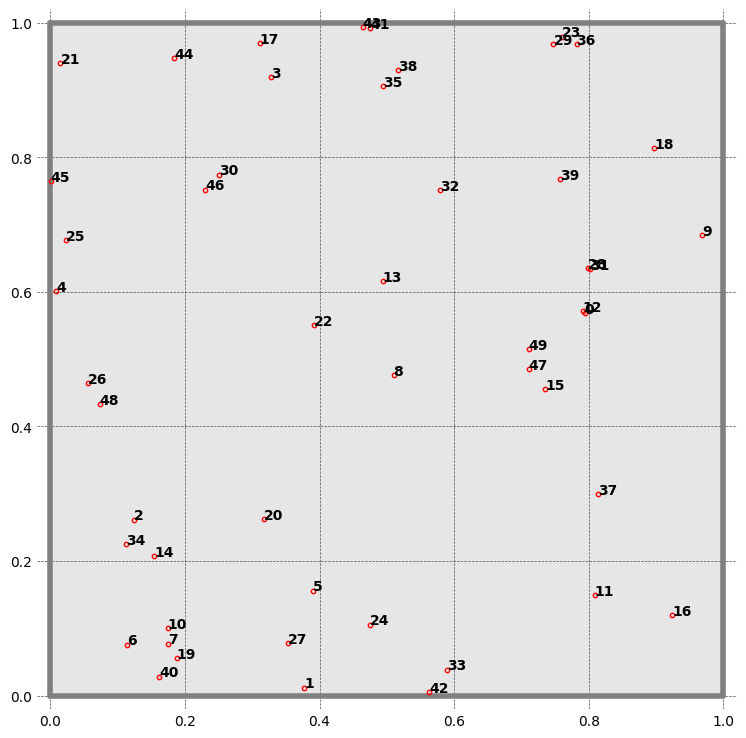

In [20]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i, xy=Env.objects['objects'][i],fontweight='bold', fontsize=10)
Env.plot_environment(gridlines=True, fig=fig, ax=ax) #visualises current environment with walls and objects
plt.show()

In [21]:
Ag = Agent(Env)

# agent configs
# Ag.pos = start_pos
Ag.thigmotaxis = 0.2

In [22]:
MINUTES = 60

In [23]:
for i in range(int(MINUTES*60/Ag.dt)):
    Ag.update()

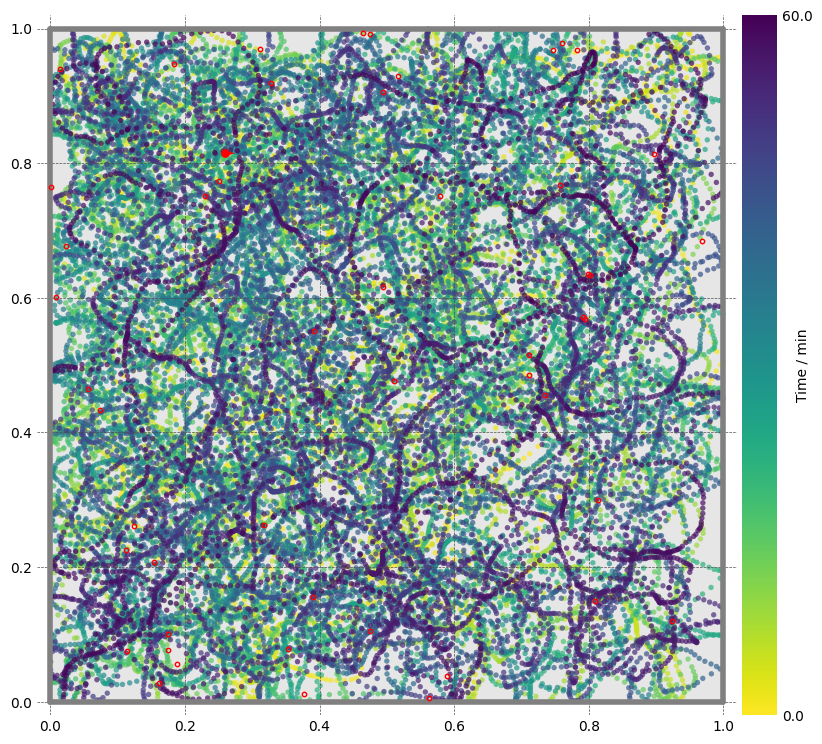

In [24]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax)
plt.show()

# init dfbase

In [25]:
dfbase = pd.DataFrame(Ag.history).copy()
print(dfbase.shape)
dfbase.head(2)

(72000, 6)


,t,pos,distance_travelled,vel,rot_vel,head_direction
0,0.05,"[0.40726392798989225, 0.7440403573045435]",0.004659,"[-0.08373563301107168, -0.040866322428685375]",1.624310,"[-0.9211063268074283, -0.38931110273832015]"
1,0.10,"[0.4026232822198967, 0.7417207576216707]",0.009847,"[-0.09281291539991132, -0.0463919936574575]",0.189775,"[-0.9126425051271226, -0.40875867921707787]"


In [26]:
df = dfbase.copy()
df.shape

(72000, 6)

## adding obj pos and names to dfbase

In [27]:
Env.objects.keys()

dict_keys(['objects', 'object_types', 'object_names'])

In [28]:
for i in range(NUM_OF_CUES):
    cue_dict = {f'obj_{i}_pos':[Env.objects['objects'][i] for _ in df.index],
         f'obj_{i}_name':[Env.objects['object_names'][i] for _ in df.index],}
    cue_df = pd.DataFrame(data=cue_dict, index=df.index)  
    df = pd.concat([df, cue_df], axis=1)

In [29]:
for i in range(NUM_OF_CUES):
    cue_dict = {f'obj_{i}_pos':[Env.objects['objects'][i] for _ in ap.index],
         f'obj_{i}_name':[Env.objects['object_names'][i] for _ in ap.index]}
    cue_ap = pd.DataFrame(data=cue_dict, index=ap.index)  
    ap = pd.concat([ap, cue_ap], axis=1)
    # df[f'obj_{i}_pos'] = [Env.objects['objects'][i] for _ in df.index]
    # df[f'obj_{i}_name'] = [Env.objects['object_names'][i] for _ in df.index]

In [30]:
ap.head()

,X,Y,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,obj_3_pos,...,obj_45_pos,obj_45_name,obj_46_pos,obj_46_name,obj_47_pos,obj_47_name,obj_48_pos,obj_48_name,obj_49_pos,obj_49_name
0,0.00,0.0,"[0.0, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,"[0.0006419453025791055, 0.7644949693109669]",KSTR,"[0.2297926775674296, 0.7519389941255517]",JYAC,"[0.7104956359310773, 0.4854665963865711]",CGCK,"[0.07351092696752082, 0.4328685977704344]",HCUQ,"[0.7104925496669595, 0.5146296313659643]",WDWP
1,0.01,0.0,"[0.01, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,"[0.0006419453025791055, 0.7644949693109669]",KSTR,"[0.2297926775674296, 0.7519389941255517]",JYAC,"[0.7104956359310773, 0.4854665963865711]",CGCK,"[0.07351092696752082, 0.4328685977704344]",HCUQ,"[0.7104925496669595, 0.5146296313659643]",WDWP
2,0.02,0.0,"[0.02, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,"[0.0006419453025791055, 0.7644949693109669]",KSTR,"[0.2297926775674296, 0.7519389941255517]",JYAC,"[0.7104956359310773, 0.4854665963865711]",CGCK,"[0.07351092696752082, 0.4328685977704344]",HCUQ,"[0.7104925496669595, 0.5146296313659643]",WDWP
3,0.03,0.0,"[0.03, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,"[0.0006419453025791055, 0.7644949693109669]",KSTR,"[0.2297926775674296, 0.7519389941255517]",JYAC,"[0.7104956359310773, 0.4854665963865711]",CGCK,"[0.07351092696752082, 0.4328685977704344]",HCUQ,"[0.7104925496669595, 0.5146296313659643]",WDWP
4,0.04,0.0,"[0.04, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,"[0.0006419453025791055, 0.7644949693109669]",KSTR,"[0.2297926775674296, 0.7519389941255517]",JYAC,"[0.7104956359310773, 0.4854665963865711]",CGCK,"[0.07351092696752082, 0.4328685977704344]",HCUQ,"[0.7104925496669595, 0.5146296313659643]",WDWP


In [31]:
df.shape

(72000, 106)

In [32]:
df.head(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,obj_45_pos,obj_45_name,obj_46_pos,obj_46_name,obj_47_pos,obj_47_name,obj_48_pos,obj_48_name,obj_49_pos,obj_49_name
0,0.05,"[0.40726392798989225, 0.7440403573045435]",0.004659,"[-0.08373563301107168, -0.040866322428685375]",1.624310,"[-0.9211063268074283, -0.38931110273832015]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,...,"[0.0006419453025791055, 0.7644949693109669]",KSTR,"[0.2297926775674296, 0.7519389941255517]",JYAC,"[0.7104956359310773, 0.4854665963865711]",CGCK,"[0.07351092696752082, 0.4328685977704344]",HCUQ,"[0.7104925496669595, 0.5146296313659643]",WDWP
1,0.10,"[0.4026232822198967, 0.7417207576216707]",0.009847,"[-0.09281291539991132, -0.0463919936574575]",0.189775,"[-0.9126425051271226, -0.40875867921707787]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,...,"[0.0006419453025791055, 0.7644949693109669]",KSTR,"[0.2297926775674296, 0.7519389941255517]",JYAC,"[0.7104956359310773, 0.4854665963865711]",CGCK,"[0.07351092696752082, 0.4328685977704344]",HCUQ,"[0.7104925496669595, 0.5146296313659643]",WDWP


## measure distances to objs

In [33]:
for i in range(NUM_OF_CUES):
    dist_cue_dict = {f'dist_to_obj_{i}': df.apply(apply_eucd_dist, axis=1, obj=i)}
    dist_cue_df = pd.DataFrame(data=dist_cue_dict, index=df.index)
    df = pd.concat([df, dist_cue_df], axis=1)

In [34]:
for i in range(NUM_OF_CUES):
    dist_cue_dict = {f'dist_to_obj_{i}': ap.apply(apply_eucd_dist, axis=1, obj=i)}
    dist_cue_ap = pd.DataFrame(data=dist_cue_dict, index=ap.index)
    ap = pd.concat([ap, dist_cue_ap], axis=1)

In [35]:
ap.head()

,X,Y,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,obj_3_pos,...,dist_to_obj_40,dist_to_obj_41,dist_to_obj_42,dist_to_obj_43,dist_to_obj_44,dist_to_obj_45,dist_to_obj_46,dist_to_obj_47,dist_to_obj_48,dist_to_obj_49
0,0.00,0.0,"[0.0, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,0.164612,1.099563,0.563351,1.096278,0.964612,0.764495,0.786268,0.860513,0.439066,0.877293
1,0.01,0.0,"[0.01, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,0.154772,1.095282,0.553351,1.092082,0.962750,0.764552,0.783404,0.852275,0.437503,0.869214
2,0.02,0.0,"[0.02, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,0.144953,1.091076,0.543352,1.087961,0.960989,0.764740,0.780657,0.844075,0.436164,0.861176
3,0.03,0.0,"[0.03, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,0.135160,1.086946,0.533352,1.083917,0.959328,0.765058,0.778029,0.835914,0.435050,0.853179
4,0.04,0.0,"[0.04, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,0.125400,1.082892,0.523353,1.079951,0.957769,0.765507,0.775521,0.827794,0.434164,0.845224


In [36]:
f"{100*len(df)} iteracoes"

'7200000 iteracoes'

In [37]:
df.shape

(72000, 156)

In [38]:
df.tail(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,dist_to_obj_40,dist_to_obj_41,dist_to_obj_42,dist_to_obj_43,dist_to_obj_44,dist_to_obj_45,dist_to_obj_46,dist_to_obj_47,dist_to_obj_48,dist_to_obj_49
71998,3599.95,"[0.2589347586332434, 0.8145872757576452]",353.607358,"[0.14637251110458327, -0.024328459971902916]",-3.290901,"[0.9994525538676812, 0.03308462735727848]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,...,0.792155,0.279265,0.864521,0.272043,0.151780,0.263105,0.069095,0.558773,0.424371,0.542106
71999,3600.00,"[0.2682389599536125, 0.8112783585368478]",353.617233,"[0.18608402640738264, -0.06617834441594805]",-3.539671,"[0.9958461764078056, -0.09105159490065917]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,...,0.790066,0.274303,0.858182,0.267334,0.159363,0.271656,0.070706,0.549313,0.425574,0.532530


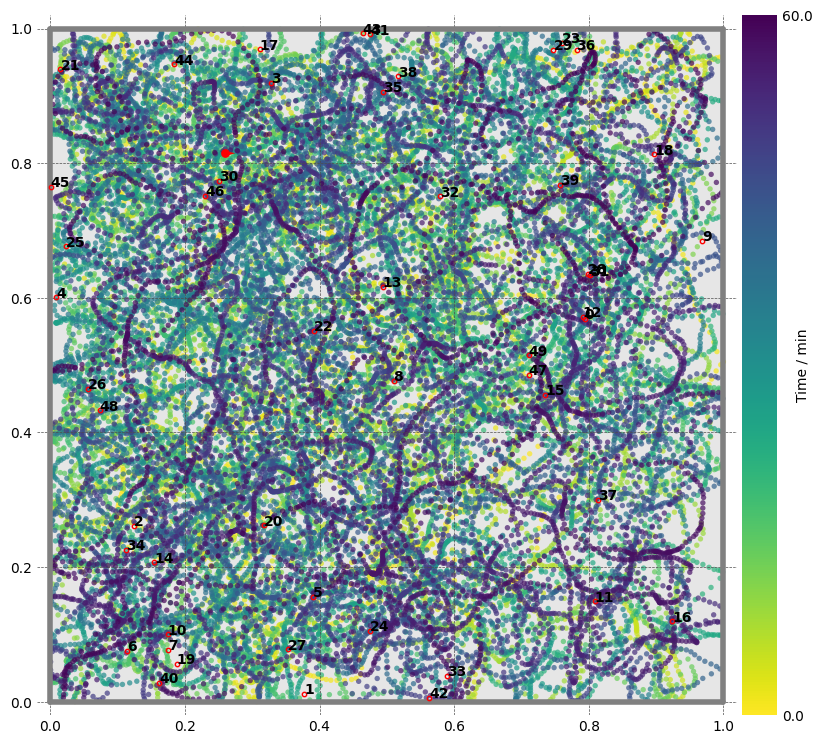

In [39]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i, xy=Env.objects['objects'][i], fontsize=10, fontweight='bold')
ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax, t_start=0, t_end=df['t'].max())

plt.show()

In [40]:
obj_names = [Env.objects['object_names'][i] for i in range(NUM_OF_CUES)]
obj_dist_cols = [f'dist_to_obj_{i}' for i in range(NUM_OF_CUES)]

# def get_position_text(x):

## create positions

In [41]:
def apply_cps_to_positions(df, obj_dist_cols):
    dft = df[obj_dist_cols].T
    dft.columns = [f't_{i:08d}' for i in range(df.T.shape[1])]
    order = [int(val.split('_')[-1]) for val in dft.sort_values(dft.columns[0]).index[:MAX_NUMBER_OF_CUES]]
    # dft.sort_values(dft.columns[0])

    positions_list = []
    position_enc_list = []
    for feat in dft.columns:
        order = [int(val.split('_')[-1]) for val in dft.sort_values(feat).index[:MAX_NUMBER_OF_CUES]]
        positions_list.append(''.join([obj_names[i] for i in order]))
        # position_enc_list.append(np.hstack([objects_encode_list[i] for i in order]))

    # len(positions_list)


    pos_state_dict = {'position_state':[val for val in positions_list],}
    pos_state_df = pd.DataFrame(data=pos_state_dict, index=df.index)
    return pd.concat([df, pos_state_df], axis=1).copy()

In [42]:
dfp = apply_cps_to_positions(df, obj_dist_cols)
dfp.shape

(72000, 157)

In [43]:
apd = apply_cps_to_positions(ap, obj_dist_cols)
apd.shape

(10201, 154)

In [44]:
apd.shape

(10201, 154)

In [45]:
len(dfp), dfp['position_state'].nunique()/len(dfp), dfp['position_state'].nunique()

(72000, 0.030125, 2169)

In [46]:
len(apd), apd['position_state'].nunique()/len(apd), apd['position_state'].nunique()

(10201, 0.1534163317321831, 1565)

In [47]:
apd.head()

,X,Y,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,obj_3_pos,...,dist_to_obj_41,dist_to_obj_42,dist_to_obj_43,dist_to_obj_44,dist_to_obj_45,dist_to_obj_46,dist_to_obj_47,dist_to_obj_48,dist_to_obj_49,position_state
0,0.00,0.0,"[0.0, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.099563,0.563351,1.096278,0.964612,0.764495,0.786268,0.860513,0.439066,0.877293,WGXVEXKNJHXTEZUESUYI
1,0.01,0.0,"[0.01, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.095282,0.553351,1.092082,0.962750,0.764552,0.783404,0.852275,0.437503,0.869214,WGXVEXKNJHXTEZUESUYI
2,0.02,0.0,"[0.02, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.091076,0.543352,1.087961,0.960989,0.764740,0.780657,0.844075,0.436164,0.861176,WGXVEXKNJHXTEZUESUYI
3,0.03,0.0,"[0.03, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.086946,0.533352,1.083917,0.959328,0.765058,0.778029,0.835914,0.435050,0.853179,WGXVEXKNJHXTEZUESUYI
4,0.04,0.0,"[0.04, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.082892,0.523353,1.079951,0.957769,0.765507,0.775521,0.827794,0.434164,0.845224,WGXVEXKNJHXTEZUESUYI


In [48]:
num_unique_pos = dfp['position_state'].nunique()
num_unique_pos

2169

In [49]:
dfp['position_state_id'] = (dfp.groupby('position_state').transform('ngroup'))
dfp['normalized_position_state_id']  = (dfp['position_state_id'] / num_unique_pos)
dfp[['position_state_id', 'normalized_position_state_id']].sample(5)

,position_state_id,normalized_position_state_id
65806,436,0.201014
13149,804,0.370678
12903,2056,0.947902
48742,614,0.283080
29374,71,0.032734


In [50]:
apd['position_state_id'] = (apd.groupby('position_state').transform('ngroup'))
apd['normalized_position_state_id']  = (apd['position_state_id'] / num_unique_pos)
apd[['position_state_id', 'normalized_position_state_id']].sample(5)

,position_state_id,normalized_position_state_id
3142,1107,0.510373
720,1473,0.679115
9548,936,0.431535
6638,1418,0.653757
5824,1446,0.666667


In [51]:
apd[['X', 'Y','position_state_id', 'position_state']].sample(5)

,X,Y,position_state_id,position_state
3831,0.94,0.37,46,BAQHPBOMZSBYNJDLWZJY
6386,0.23,0.63,802,JYACIFZNIEEYIYNFRBPS
4194,0.53,0.41,242,CPJYCGCKIEEYWDWPCBDJ
7062,0.93,0.69,1014,MIDKKTRGFKBDVESGZSBY
1599,0.84,0.15,354,EGHLWZJYBAQHDXRBZSUF


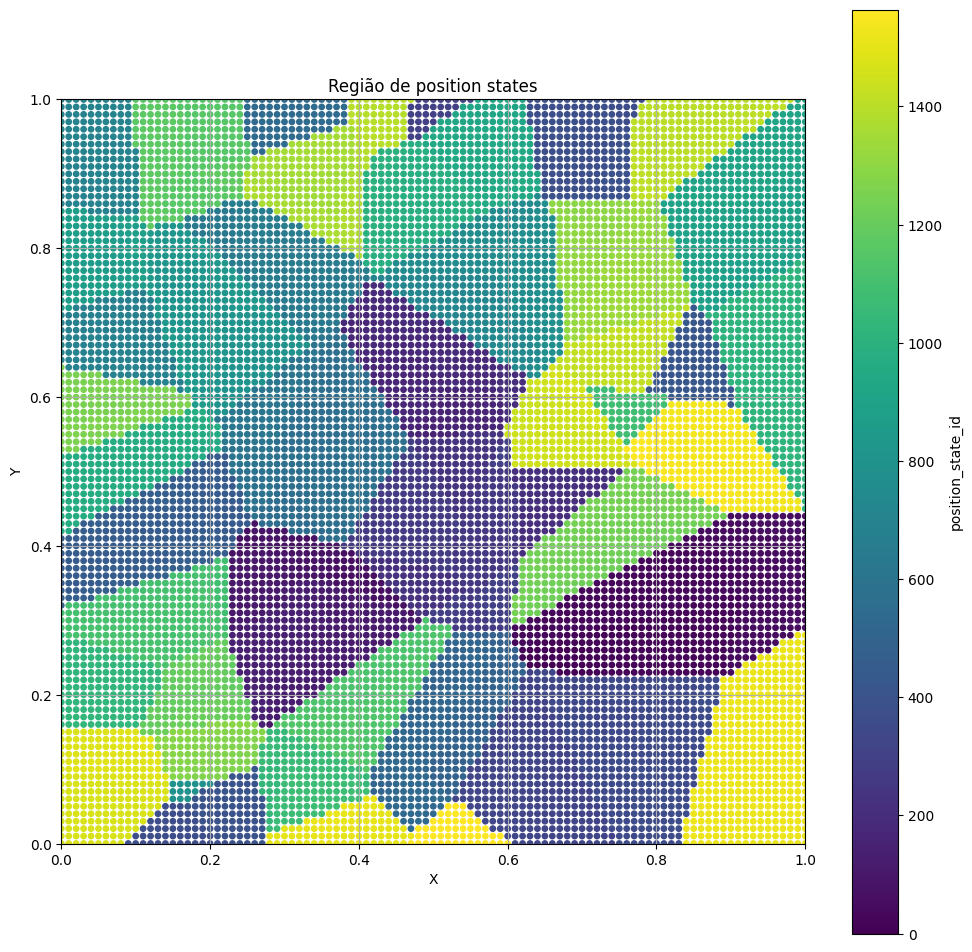

In [52]:
plt.figure(figsize=(12, 12))
scatter = plt.scatter(apd['X'], apd['Y'], c=apd['position_state_id'], cmap='viridis', s=15)
# Adiciona barra de cores
cbar = plt.colorbar(scatter)
cbar.set_label('position_state_id')

# Configurações visuais
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Região de position states')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True)
plt.gca().set_aspect('equal', adjustable='box')  # ambiente 1x1

plt.show()

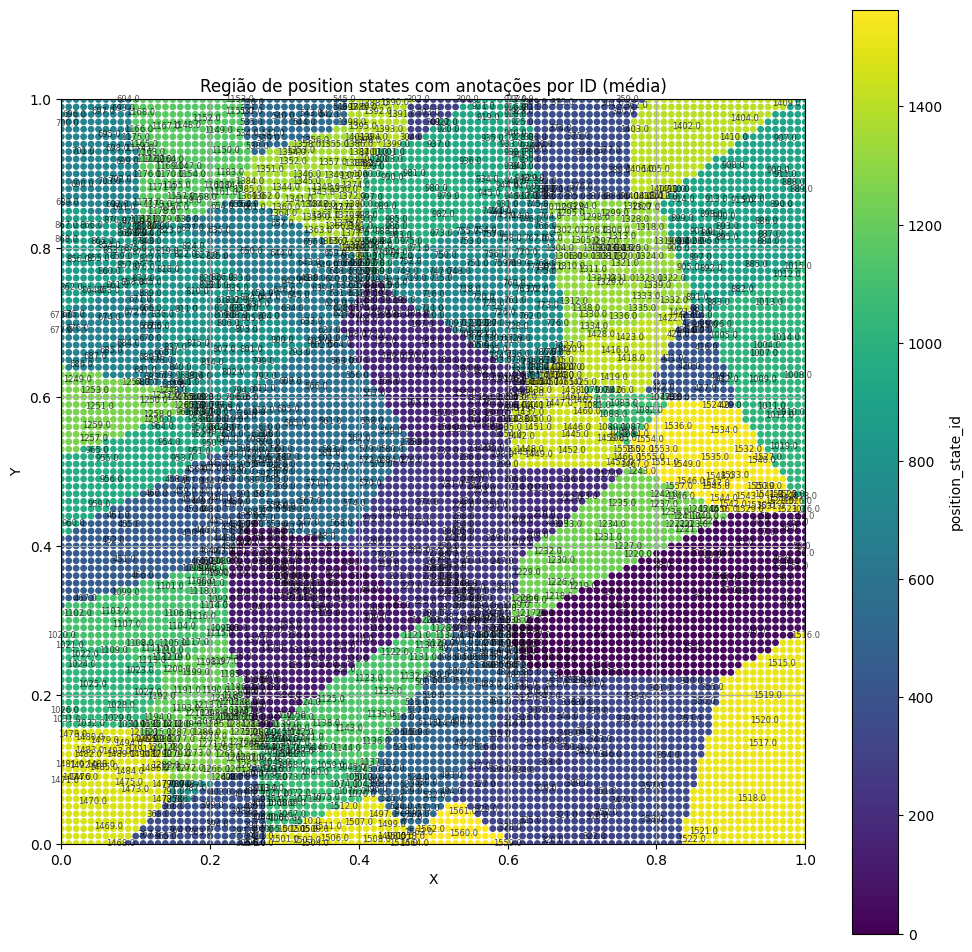

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 12))

# Scatter plot com cor por position_state_id
scatter = plt.scatter(apd['X'], apd['Y'], c=apd['position_state_id'], cmap='viridis', s=15)

# Adiciona barra de cores
cbar = plt.colorbar(scatter)
cbar.set_label('position_state_id')

# Agrupa por position_state_id e calcula média de X e Y
group_means = apd.groupby('position_state_id')[['X', 'Y']].mean().reset_index()

# Anota cada ponto médio com o ID
for _, row in group_means.iterrows():
    plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                 fontsize=6, alpha=0.7, ha='center', va='center')

# Configurações visuais
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Região de position states com anotações por ID (média)')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True)
plt.gca().set_aspect('equal', adjustable='box')

plt.show()


In [54]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_position_states(apd, grupos_destacados):
    """
    Plota os pontos do DataFrame apd (com colunas X, Y e position_state_id),
    destacando apenas os grupos na lista grupos_destacados, com anotações.

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y' e 'position_state_id'
    - grupos_destacados: lista de valores de position_state_id a serem coloridos e anotados
    """
    # Criação da máscara de seleção
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Define cores: branco ou cinza claro para os pontos não destacados
    cor_base = '#e0e0e0'
    
    plt.figure(figsize=(12, 12))

    # Plota todos os pontos em cinza claro
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10, label='Outros')

    # Plota apenas os pontos destacados com colormap
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar a média dos grupos destacados
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Adiciona colorbar apenas se houver grupos destacados
        cbar = plt.colorbar(scatter)
        cbar.set_label('position_state_id destacado')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por position_state_id')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend()
    plt.show()


In [55]:
apd['position_state_id'].nunique()

1565

In [56]:
apd.groupby('position_state_id').size().describe()

count    1565.000000
mean        6.518211
std        10.794249
min         1.000000
25%         1.000000
50%         3.000000
75%         7.000000
max       182.000000
dtype: float64

In [57]:
apd['position_state_id'].value_counts()

position_state_id
1518    182
1402    108
15       93
354      79
451      79
       ... 
957       1
961       1
622       1
610       1
359       1
Name: count, Length: 1565, dtype: int64

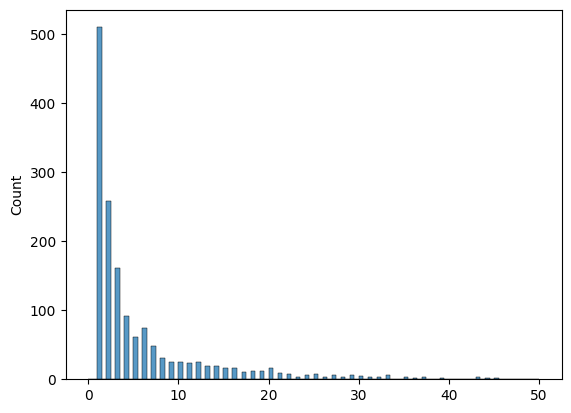

In [58]:
import seaborn as sns
sns.histplot(apd.groupby('position_state_id').size(), binwidth=0.5, binrange=(0, 50))
plt.show()

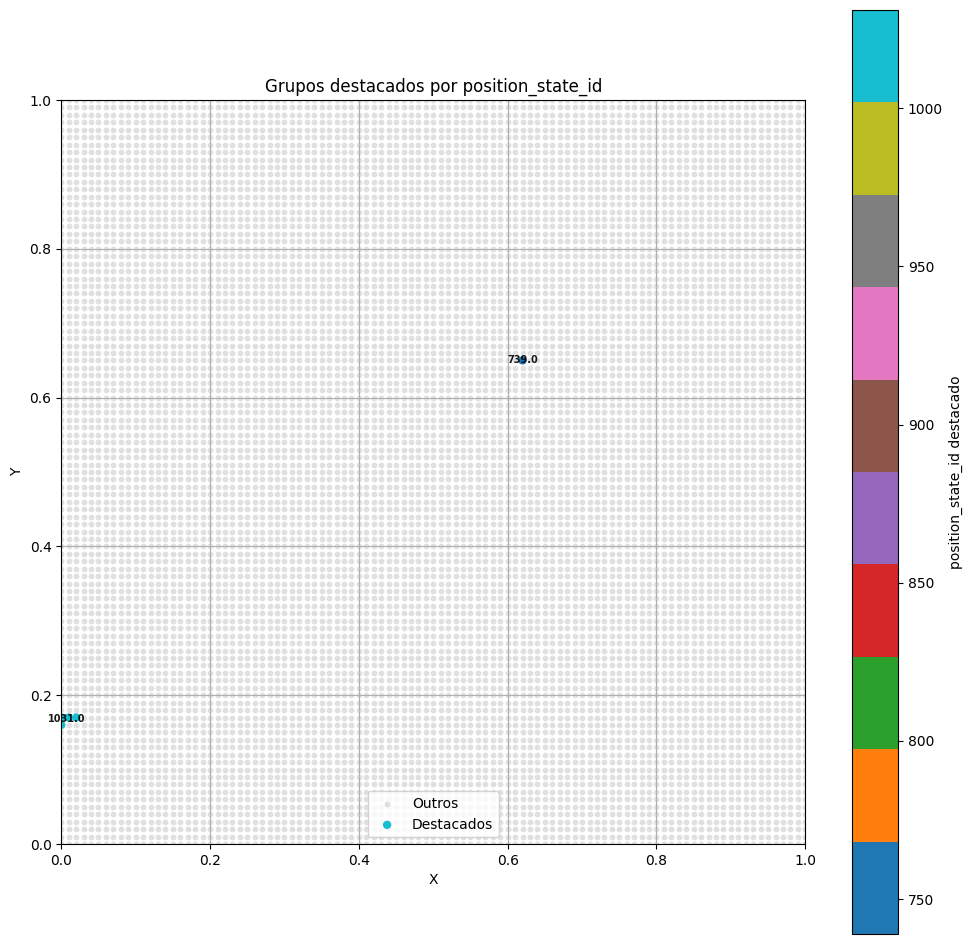

In [59]:
grupos_para_destacar = [1031, 1790, 739]
plot_position_states(apd, grupos_para_destacar)

In [60]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

def plot_position_states_imshow(apd, resolucao=100):
    """
    Plota o mapa completo de position_state_id usando imshow.
    Cada grupo é pintado com uma cor única.
    Um rótulo com o ID é anotado na posição média de cada grupo.

    Parâmetros:
    - apd: DataFrame com colunas X, Y, position_state_id
    - resolucao: tamanho da grade (resolucao x resolucao)
    """
    # Converte X, Y para coordenadas discretas da grade
    xs = (apd['X'] * (resolucao - 1)).astype(int)
    ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)  # inverte Y para alinhar com o eixo da imagem

    # Inicializa grade com valor inválido (-1)
    mapa = np.full((resolucao, resolucao), -1, dtype=int)

    # Preenche a grade com os position_state_id
    for x, y, pid in zip(xs, ys, apd['position_state_id']):
        mapa[y, x] = pid  # y = linha, x = coluna

    # IDs únicos válidos (exclui -1)
    unique_ids = np.unique(mapa)
    unique_ids = unique_ids[unique_ids >= 0]

    # Mapear IDs para índices de cor
    id_to_idx = {pid: idx for idx, pid in enumerate(unique_ids)}
    color_mapa = np.zeros_like(mapa)
    for pid, idx in id_to_idx.items():
        color_mapa[mapa == pid] = idx

    # Cria colormap discreto
    cmap = plt.cm.get_cmap('tab20', len(unique_ids))
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-0.5, len(unique_ids) + 0.5), ncolors=cmap.N)

    # Plot da imagem
    plt.figure(figsize=(15, 15))
    plt.imshow(color_mapa, cmap=cmap, norm=norm, origin='upper', extent=[0, 1, 0, 1], interpolation='none')

    # Anotar ponto médio de cada grupo
    medias = apd.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
    # for _, row in medias.iterrows():
    #     plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
    #                  fontsize=7, color='black', ha='center', va='center', fontweight='bold', alpha=0.8)

    # Layout
    plt.title("Mapa completo de position_state_id com anotações")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


In [61]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import networkx as nx

def plot_position_states_imshow_graph(apd, resolucao=100):
    """
    Plota o mapa completo de position_state_id usando imshow com coloração inteligente:
    grupos vizinhos recebem cores diferentes.

    Parâmetros:
    - apd: DataFrame com colunas X, Y, position_state_id
    - resolucao: tamanho da grade (resolucao x resolucao)
    """
    # Converte X, Y para coordenadas discretas da grade
    xs = (apd['X'] * (resolucao - 1)).astype(int)
    ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)

    # Inicializa grade com valor inválido (-1)
    mapa = np.full((resolucao, resolucao), -1, dtype=int)

    for x, y, pid in zip(xs, ys, apd['position_state_id']):
        mapa[y, x] = pid  # y = linha, x = coluna

    # IDs únicos válidos (exclui -1)
    unique_ids = np.unique(mapa)
    unique_ids = unique_ids[unique_ids >= 0]

    # --- Construção do grafo de vizinhança ---
    G = nx.Graph()
    for i in range(resolucao - 1):
        for j in range(resolucao - 1):
            pid = mapa[i, j]
            if pid == -1:
                continue
            for di, dj in [(0, 1), (1, 0)]:
                ni, nj = i + di, j + dj
                if 0 <= ni < resolucao and 0 <= nj < resolucao:
                    vizinho = mapa[ni, nj]
                    if vizinho != -1 and vizinho != pid:
                        G.add_edge(pid, vizinho)

    # --- Colorização do grafo ---
    color_map = nx.coloring.greedy_color(G, strategy='largest_first')
    max_color = max(color_map.values()) + 1

    # Mapeia position_state_id para índices de cor
    pid_to_color_idx = {pid: color_map.get(pid, 0) for pid in unique_ids}

    # Preenche o mapa de cores
    color_mapa = np.zeros_like(mapa, dtype=int)
    for pid in unique_ids:
        idx = pid_to_color_idx[pid]
        color_mapa[mapa == pid] = idx

    # Colormap e normalização
    cmap = plt.cm.get_cmap('tab20', max_color)
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-0.5, max_color + 0.5), ncolors=cmap.N)

    # --- Plot ---
    plt.figure(figsize=(15, 15))
    plt.imshow(color_mapa, cmap=cmap, norm=norm, origin='upper',
               extent=[0, 1, 0, 1], interpolation='none')

    # Layout
    plt.title("Mapa com coloração inteligente (grupos vizinhos com cores distintas)")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


In [62]:
# grupos_para_destacar = [2887, 1469, 1077]
# plot_position_states_imshow(apd,grupos_para_destacar)


/tmp/ipykernel_1991/1607293999.py:37: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', len(unique_ids))


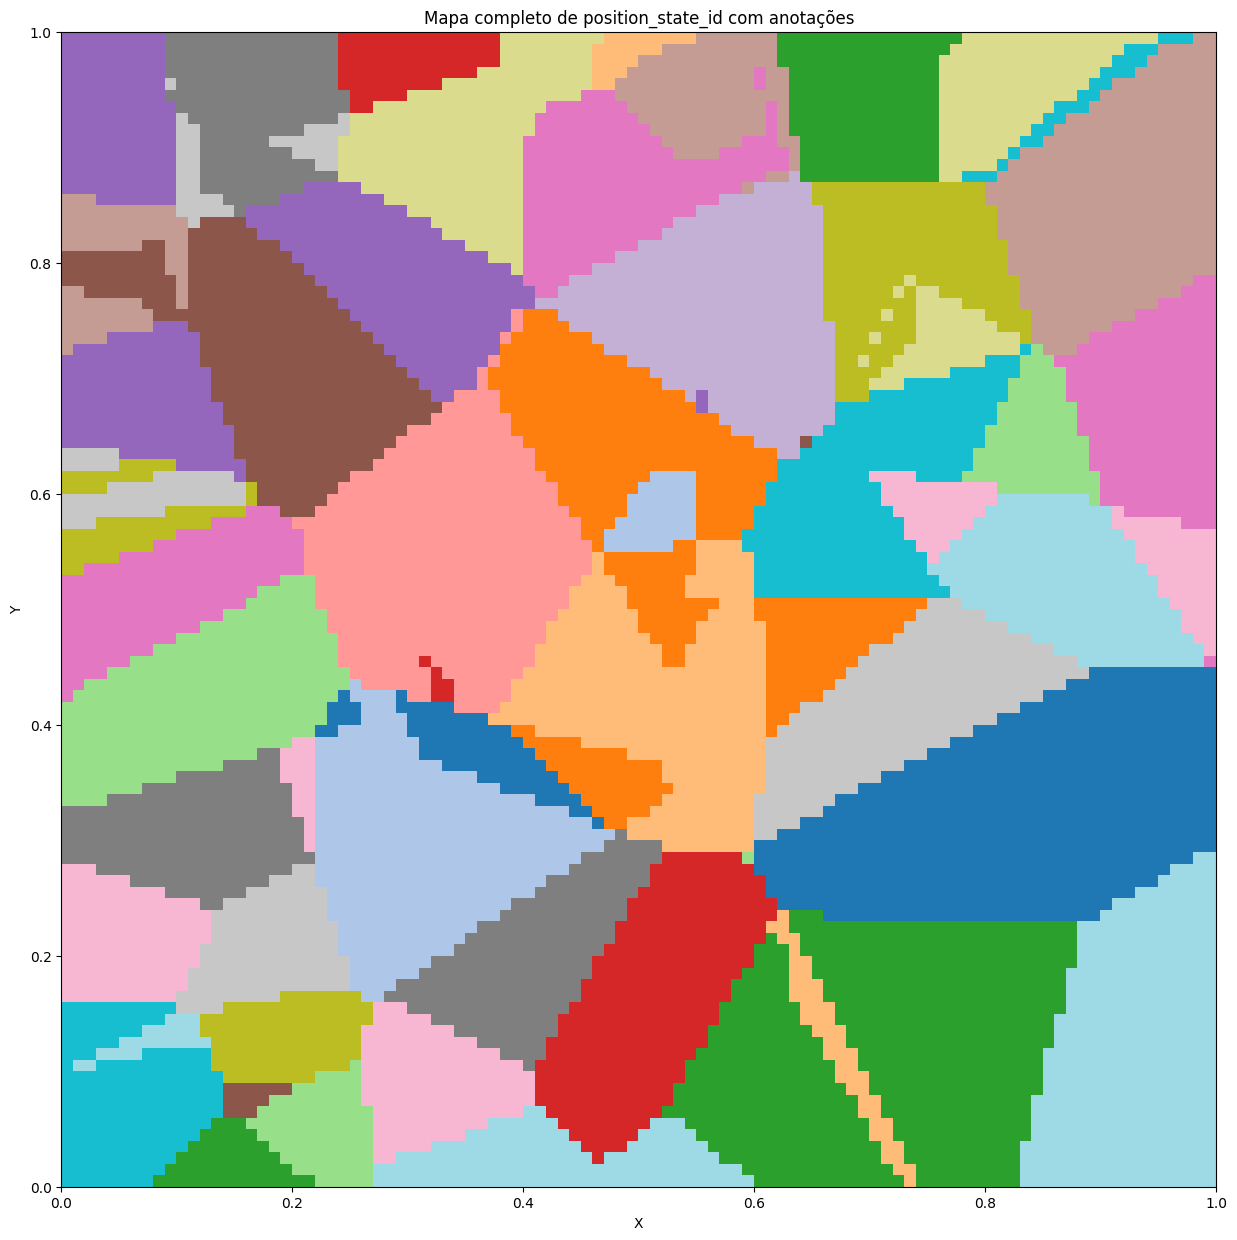

In [63]:
plot_position_states_imshow(apd)

/tmp/ipykernel_1991/1441942947.py:57: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', max_color)


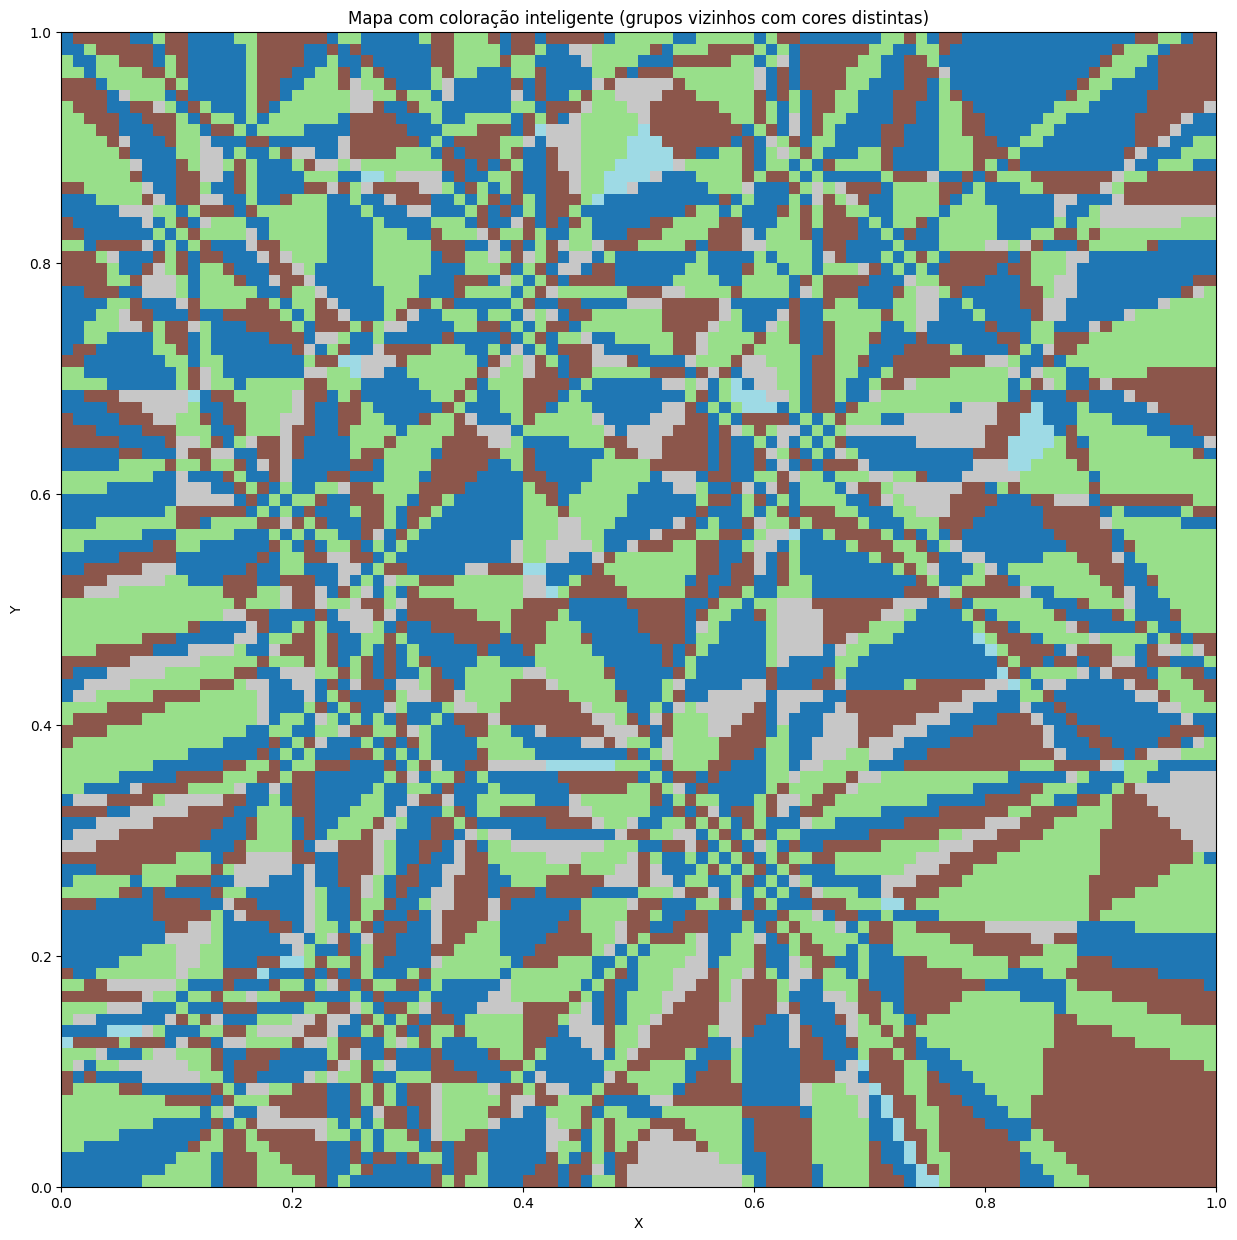

In [64]:
plot_position_states_imshow_graph(apd,)

In [65]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import networkx as nx

def plot_position_states_with_objects(apd, Env, resolucao=100):
    """
    Plota o mapa de position_state_id com coloração inteligente para vizinhos
    e insere pontos de objetos sobrepostos via scatter (em preto).

    Parâmetros:
    - apd: DataFrame com colunas X, Y, position_state_id
    - Env: objeto com atributo Env.objects['objects'] (array Nx2 de coordenadas em [0,1])
    - resolucao: resolução da grade (resolucao x resolucao)
    """
    # Converte X, Y para coordenadas da grade
    xs = (apd['X'] * (resolucao - 1)).astype(int)
    ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)

    # Inicializa grade
    mapa = np.full((resolucao, resolucao), -1, dtype=int)
    for x, y, pid in zip(xs, ys, apd['position_state_id']):
        mapa[y, x] = pid

    # IDs válidos
    unique_ids = np.unique(mapa)
    unique_ids = unique_ids[unique_ids >= 0]

    # Grafo de vizinhança
    G = nx.Graph()
    for i in range(resolucao - 1):
        for j in range(resolucao - 1):
            pid = mapa[i, j]
            if pid == -1:
                continue
            for di, dj in [(0, 1), (1, 0)]:
                ni, nj = i + di, j + dj
                if 0 <= ni < resolucao and 0 <= nj < resolucao:
                    vizinho = mapa[ni, nj]
                    if vizinho != -1 and vizinho != pid:
                        G.add_edge(pid, vizinho)

    # Colorir com greedy coloring
    color_map = nx.coloring.greedy_color(G, strategy='largest_first')
    max_color = max(color_map.values()) + 1
    pid_to_color_idx = {pid: color_map.get(pid, 0) for pid in unique_ids}

    # Construir mapa de cores
    color_mapa = np.zeros_like(mapa, dtype=int)
    for pid in unique_ids:
        color_mapa[mapa == pid] = pid_to_color_idx[pid]

    # Colormap e normalização
    cmap = plt.cm.get_cmap('tab20', max_color)
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-0.5, max_color + 0.5), ncolors=cmap.N)

    # --- Plot ---
    plt.figure(figsize=(15, 15))
    plt.imshow(color_mapa, cmap=cmap, norm=norm, origin='upper',
               extent=[0, 1, 0, 1], interpolation='none')

    # Scatter de objetos
    objetos = Env.objects['objects']
    plt.scatter(objetos[:, 0], objetos[:, 1], color='black', s=40, label='Objetos')

    # Layout
    plt.title("Mapa de position_state_id com objetos sobrepostos")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.legend()
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


/tmp/ipykernel_1991/281748945.py:54: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', max_color)


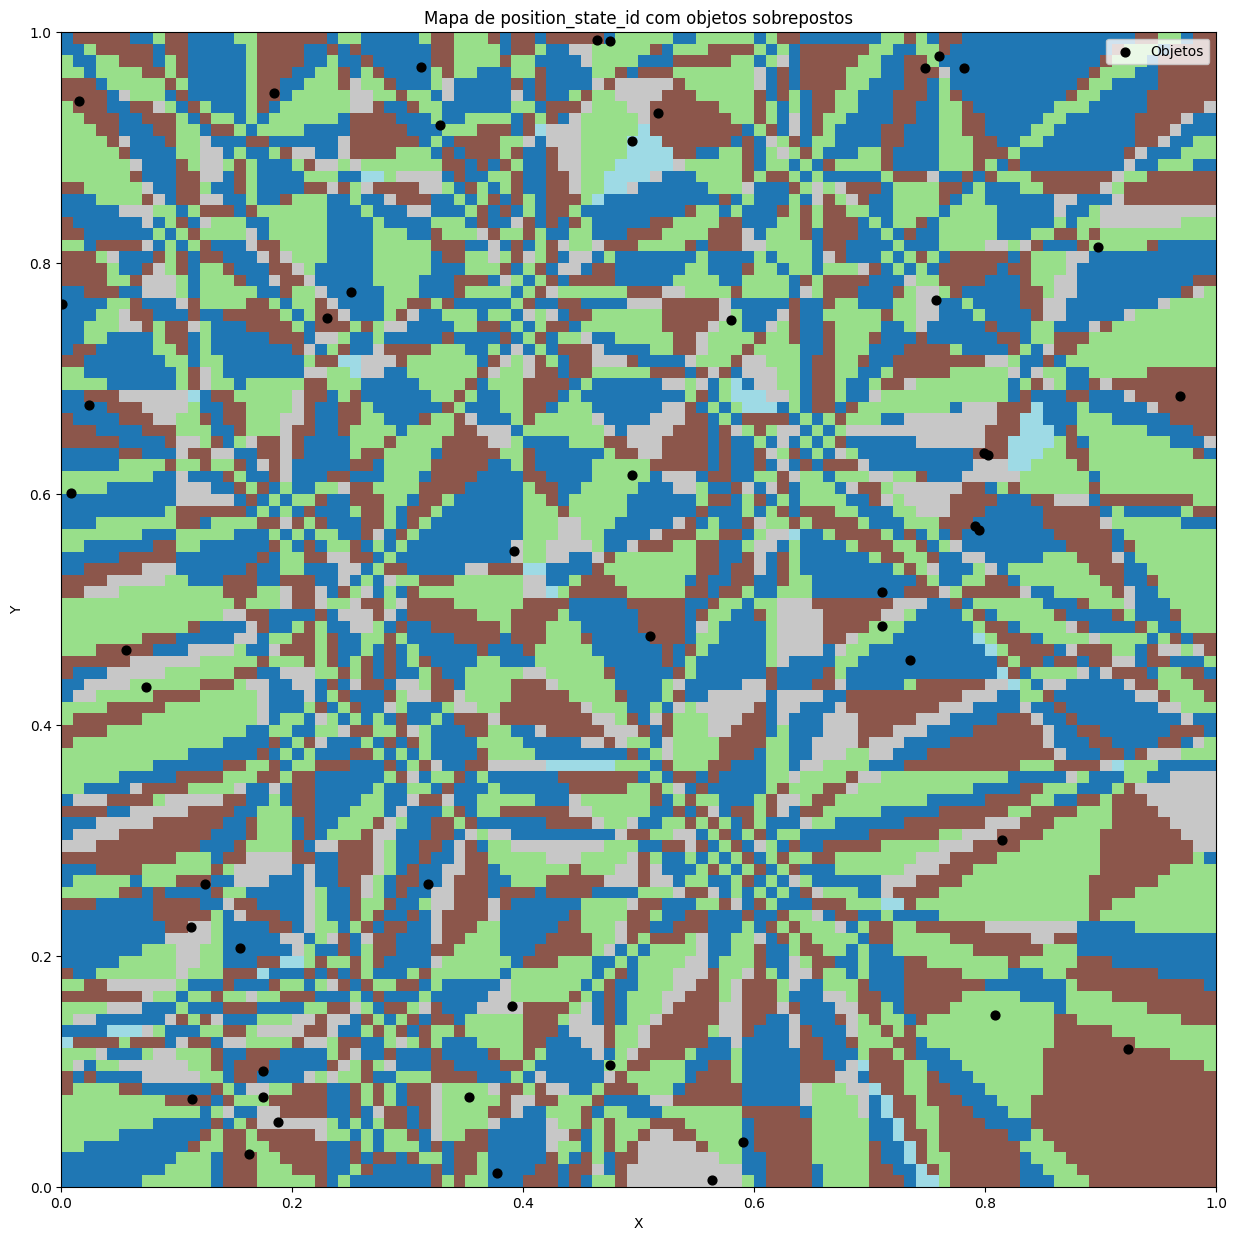

In [66]:
plot_position_states_with_objects(apd, Env)

In [67]:
apd.head()

,X,Y,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,obj_3_pos,...,dist_to_obj_43,dist_to_obj_44,dist_to_obj_45,dist_to_obj_46,dist_to_obj_47,dist_to_obj_48,dist_to_obj_49,position_state,position_state_id,normalized_position_state_id
0,0.00,0.0,"[0.0, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.096278,0.964612,0.764495,0.786268,0.860513,0.439066,0.877293,WGXVEXKNJHXTEZUESUYI,1469,0.677271
1,0.01,0.0,"[0.01, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.092082,0.962750,0.764552,0.783404,0.852275,0.437503,0.869214,WGXVEXKNJHXTEZUESUYI,1469,0.677271
2,0.02,0.0,"[0.02, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.087961,0.960989,0.764740,0.780657,0.844075,0.436164,0.861176,WGXVEXKNJHXTEZUESUYI,1469,0.677271
3,0.03,0.0,"[0.03, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.083917,0.959328,0.765058,0.778029,0.835914,0.435050,0.853179,WGXVEXKNJHXTEZUESUYI,1469,0.677271
4,0.04,0.0,"[0.04, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.079951,0.957769,0.765507,0.775521,0.827794,0.434164,0.845224,WGXVEXKNJHXTEZUESUYI,1469,0.677271


## get change of pos

In [68]:
dfp['last_position_state_id'] = (dfp['position_state_id'].shift(1))
dfp.shape

(72000, 160)

<Axes: >

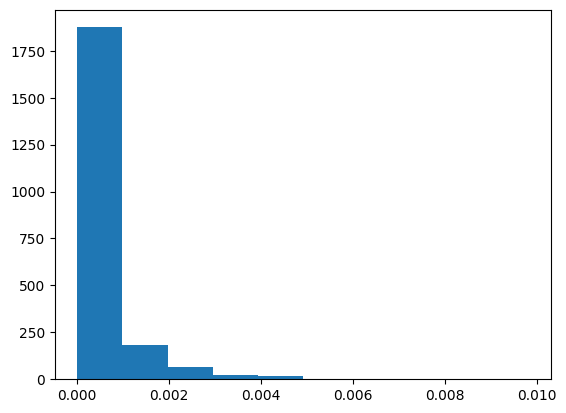

In [69]:
dfp['position_state_id'].value_counts(normalize=True,).hist(grid=False)

In [71]:
dfp[['position_state', 'position_state_id', 'last_position_state_id',]].iloc[8:12]

,position_state,position_state_id,last_position_state_id
8,IFZNJYACULXMCBDJIEEY,870,870.0
9,IFZNJYACULXMCBDJIEEY,870,870.0
10,IFZNJYACULXMCBDJIEEY,870,870.0
11,IFZNJYACULXMIEEYCBDJ,876,870.0


In [72]:
dfp[['position_state_id', 'last_position_state_id']].dtypes

position_state_id           int64
last_position_state_id    float64
dtype: object

In [73]:
dfp.shape

(72000, 160)

In [74]:
len(dfp['position_state_id'])

72000

In [75]:
change_dict_ = {'change_of_position_state':[int(pos!=last_pos) for pos, last_pos in zip(dfp['position_state_id'].astype('float'), dfp['last_position_state_id'])]}
change_dict_df = pd.DataFrame(change_dict_)

print(change_dict_df.shape)
# dfp = pd.concat([dfp, change_dict_df], ignore_index=True, axis=0)

(72000, 1)


In [76]:
dfp.shape

(72000, 160)

In [77]:
dfp['change_of_position_state'] = (change_dict_df['change_of_position_state'])

In [78]:
dfp.shape

(72000, 161)

In [79]:
# dfp['change_of_position_state'].values

In [80]:
dfp[['position_state', 'position_state_id', 'last_position_state_id', 'change_of_position_state']].iloc[8:12]

,position_state,position_state_id,last_position_state_id,change_of_position_state
8,IFZNJYACULXMCBDJIEEY,870,870.0,0
9,IFZNJYACULXMCBDJIEEY,870,870.0,0
10,IFZNJYACULXMCBDJIEEY,870,870.0,0
11,IFZNJYACULXMIEEYCBDJ,876,870.0,1


In [81]:
dfp[dfp['change_of_position_state'] == 1][['position_state_id', 'last_position_state_id', 'change_of_position_state']].head()

,position_state_id,last_position_state_id,change_of_position_state
0,235,NaN,1
1,240,235.0,1
2,846,240.0,1
4,858,846.0,1
6,859,858.0,1


In [82]:
dfp[dfp['change_of_position_state'] == 1].shape

(18613, 161)

In [83]:
dfp['change_of_position_state'].mean()

0.2585138888888889

# train df

In [84]:
dfc = dfp[dfp['change_of_position_state'] == 1].iloc[1:].reset_index(drop=True).copy()
dfc.shape

(18612, 161)

In [87]:
dfc.head(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,dist_to_obj_45,dist_to_obj_46,dist_to_obj_47,dist_to_obj_48,dist_to_obj_49,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.10,"[0.4026232822198967, 0.7417207576216707]",0.009847,"[-0.09281291539991132, -0.0463919936574575]",0.189775,"[-0.9126425051271226, -0.40875867921707787]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,...,0.402626,0.173132,0.400564,0.451336,0.382562,CBDJIFZNJYACJEFEMDQC,240,0.110650,235.0,1
1,0.15,"[0.3976118494689565, 0.7399640928963773]",0.015157,"[-0.10022865501880363, -0.035133294505866886]",-2.527519,"[-0.923718739965175, -0.3830713894787102]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,...,0.397727,0.168246,0.403318,0.446485,0.385577,IFZNCBDJJYACJEFEIEEY,846,0.390041,240.0,1


In [88]:
dfc.columns

Index(['t', 'pos', 'distance_travelled', 'vel', 'rot_vel', 'head_direction',
       'obj_0_pos', 'obj_0_name', 'obj_1_pos', 'obj_1_name',
       ...
       'dist_to_obj_45', 'dist_to_obj_46', 'dist_to_obj_47', 'dist_to_obj_48',
       'dist_to_obj_49', 'position_state', 'position_state_id',
       'normalized_position_state_id', 'last_position_state_id',
       'change_of_position_state'],
      dtype='object', length=161)

In [91]:
columns_to_keep = [
    't',
    'pos',
    'distance_travelled',
    'vel',
    'rot_vel',
    'head_direction',
    'position_state',
    'position_state_id',
    'normalized_position_state_id',
    'last_position_state_id',
    'change_of_position_state',
]

In [ ]:
# print(dfc[columns_to_keep].shape)
# dfc[columns_to_keep].to_csv(r'/home/mgteus/workspace/navitrans/bert_trainset.csv', index=False)

(18612, 11)


In [ ]:
# apd.to_parquet(r'apd.gzip')

In [93]:
dfc[columns_to_keep].head(5)

,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.10,"[0.4026232822198967, 0.7417207576216707]",0.009847,"[-0.09281291539991132, -0.0463919936574575]",0.189775,"[-0.9126425051271226, -0.40875867921707787]",CBDJIFZNJYACJEFEMDQC,240,0.110650,235.0,1
1,0.15,"[0.3976118494689565, 0.7399640928963773]",0.015157,"[-0.10022865501880363, -0.035133294505866886]",-2.527519,"[-0.923718739965175, -0.3830713894787102]",IFZNCBDJJYACJEFEIEEY,846,0.390041,240.0,1
2,0.25,"[0.3871869069670582, 0.7382276043027474]",0.025731,"[-0.1157980395373881, -0.015827543423303503]",-1.306173,"[-0.9651324753611911, -0.2617619242807858]",IFZNJYACCBDJIEEYULXM,858,0.395574,846.0,1
3,0.35,"[0.37094048877761576, 0.7407068703028369]",0.042363,"[-0.1685047256200367, 0.05150216436610178]",-6.177608,"[-0.9997341035096768, -0.023059104052473488]",IFZNJYACCBDJULXMIEEY,859,0.396035,858.0,1
4,0.40,"[0.363635652896056, 0.7433210276800175]",0.050122,"[-0.14609671763119558, 0.05228314754361252]",-0.940823,"[-0.9951463668119384, 0.09840583631573364]",IFZNJYACULXMCBDJIEEY,870,0.401107,859.0,1


In [94]:
dfc['position_state'].values[:3]

array(['CBDJIFZNJYACJEFEMDQC', 'IFZNCBDJJYACJEFEIEEY',
       'IFZNJYACCBDJIEEYULXM'], dtype=object)

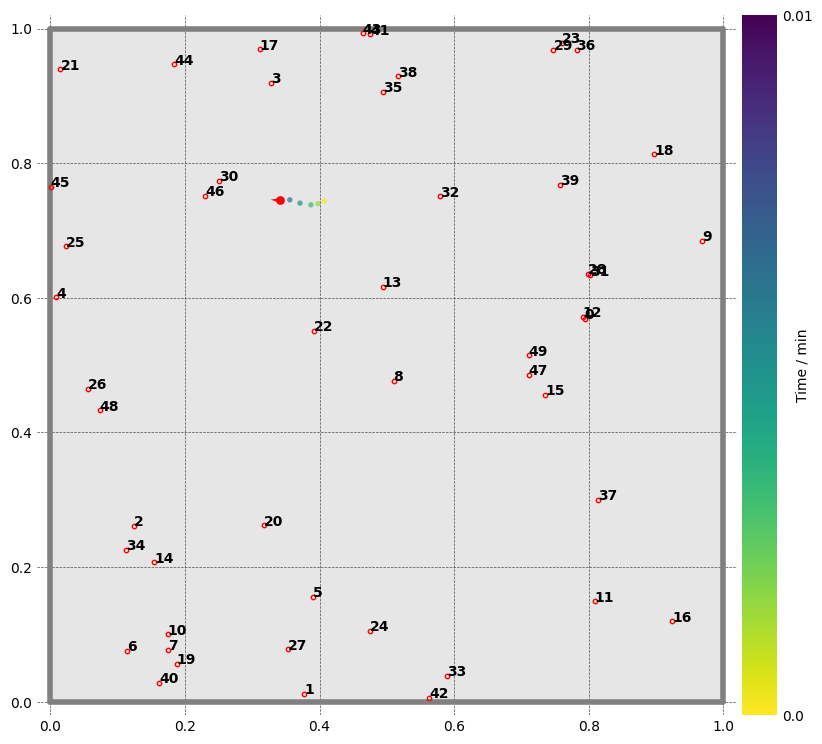

In [95]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i, xy=Env.objects['objects'][i], fontsize=10, fontweight='bold')
ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax, t_start=0, t_end=dfc['t'].values[5])

plt.show()

# FIM

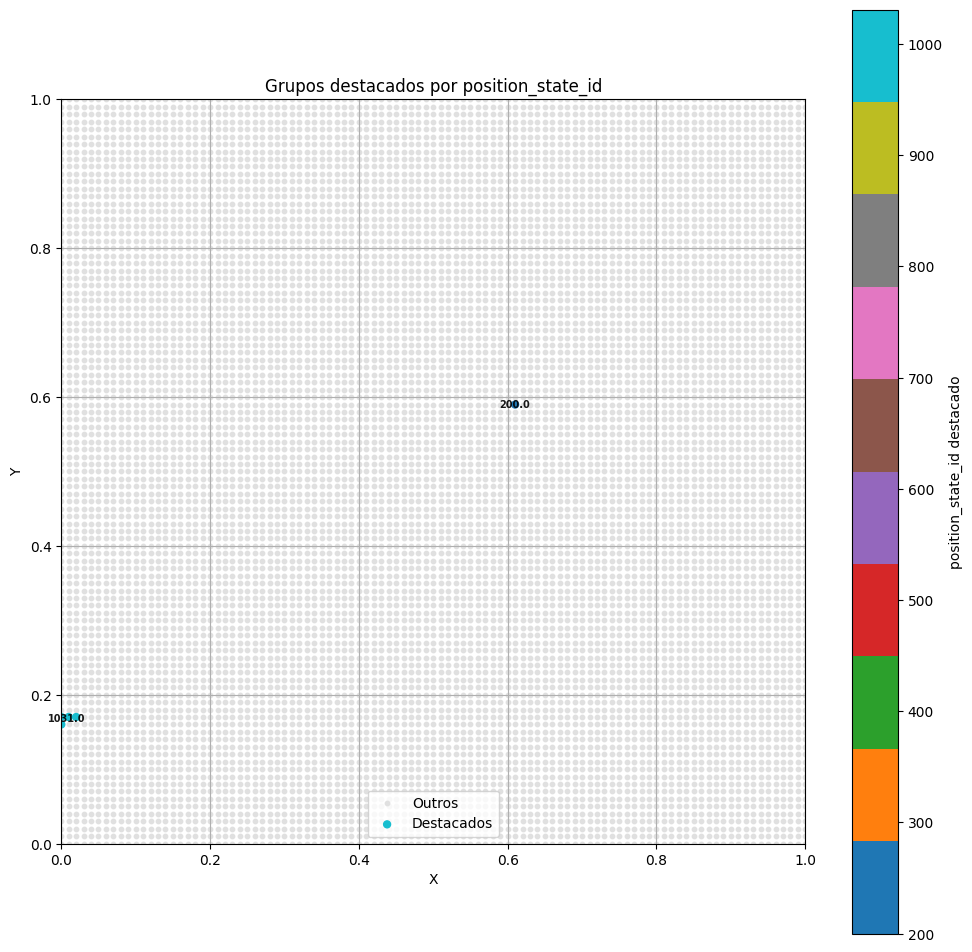

In [ ]:
grupos_para_destacar = [1031,200]
plot_position_states(apd, grupos_para_destacar)

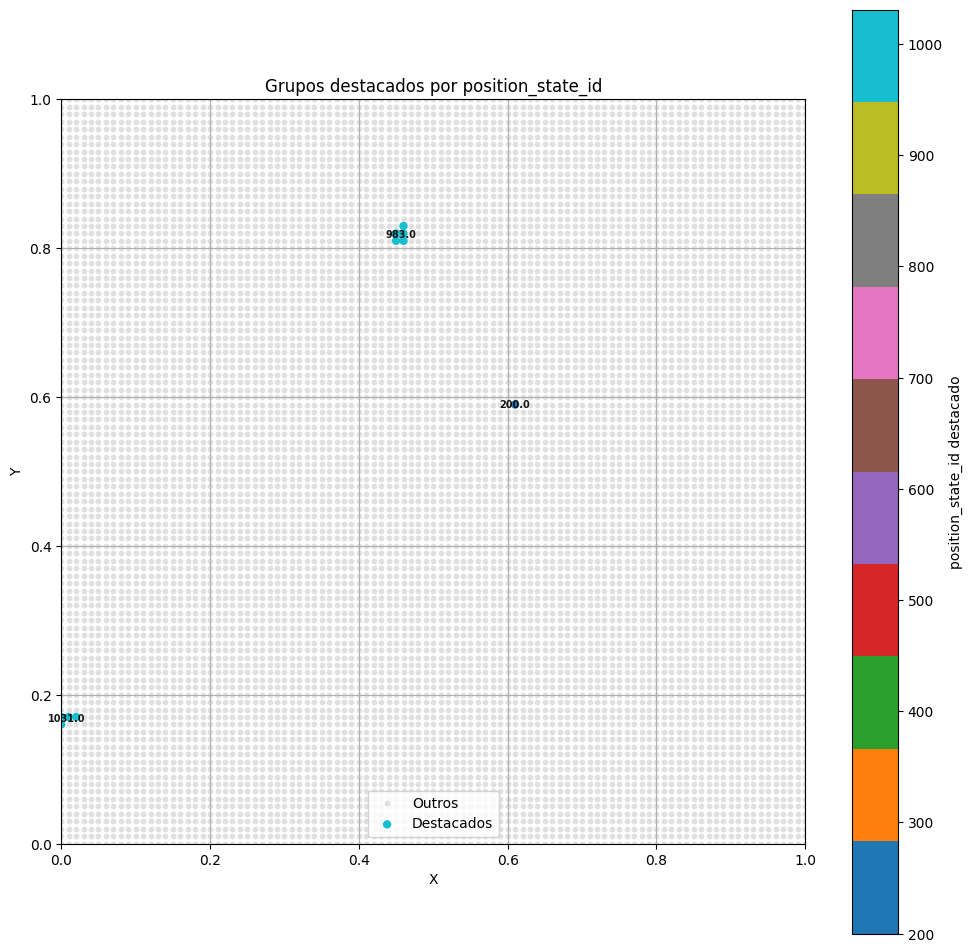

In [98]:
grupos_para_destacar = [200, 983, 1031]
plot_position_states(apd, grupos_para_destacar)

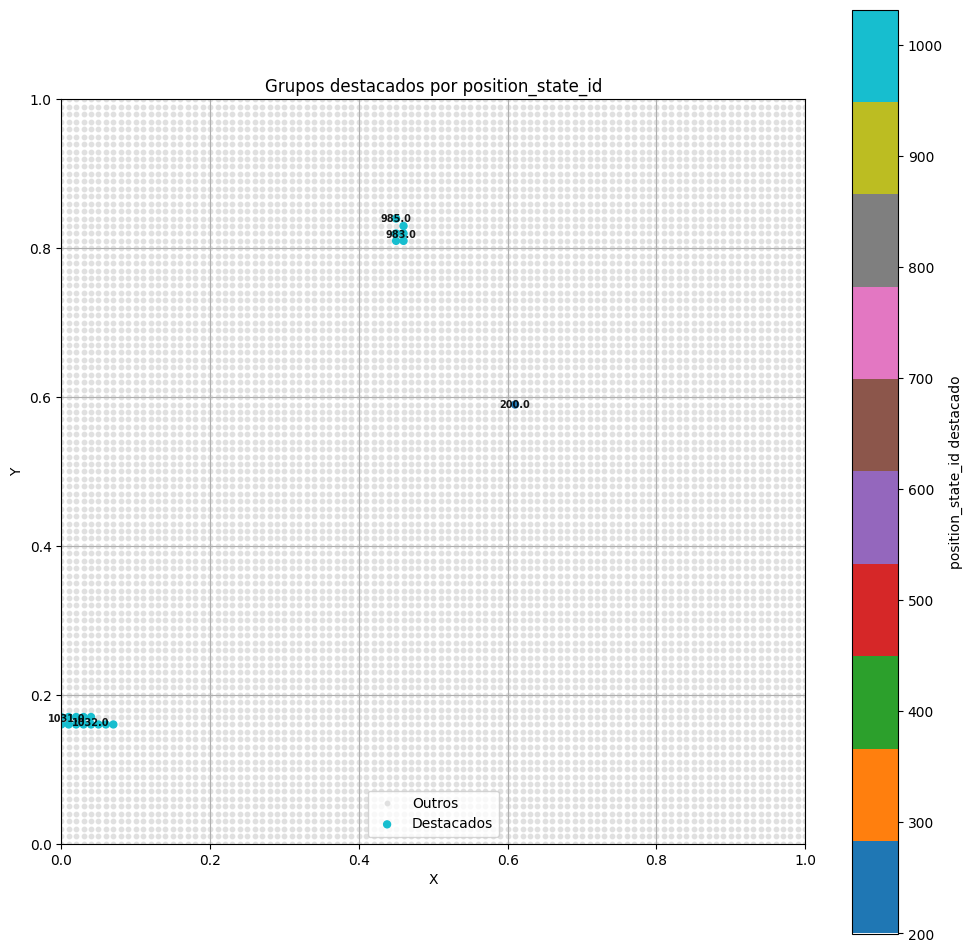

In [99]:
grupos_para_destacar = [200, 985, 983, 1032, 1031]
plot_position_states(apd, grupos_para_destacar)

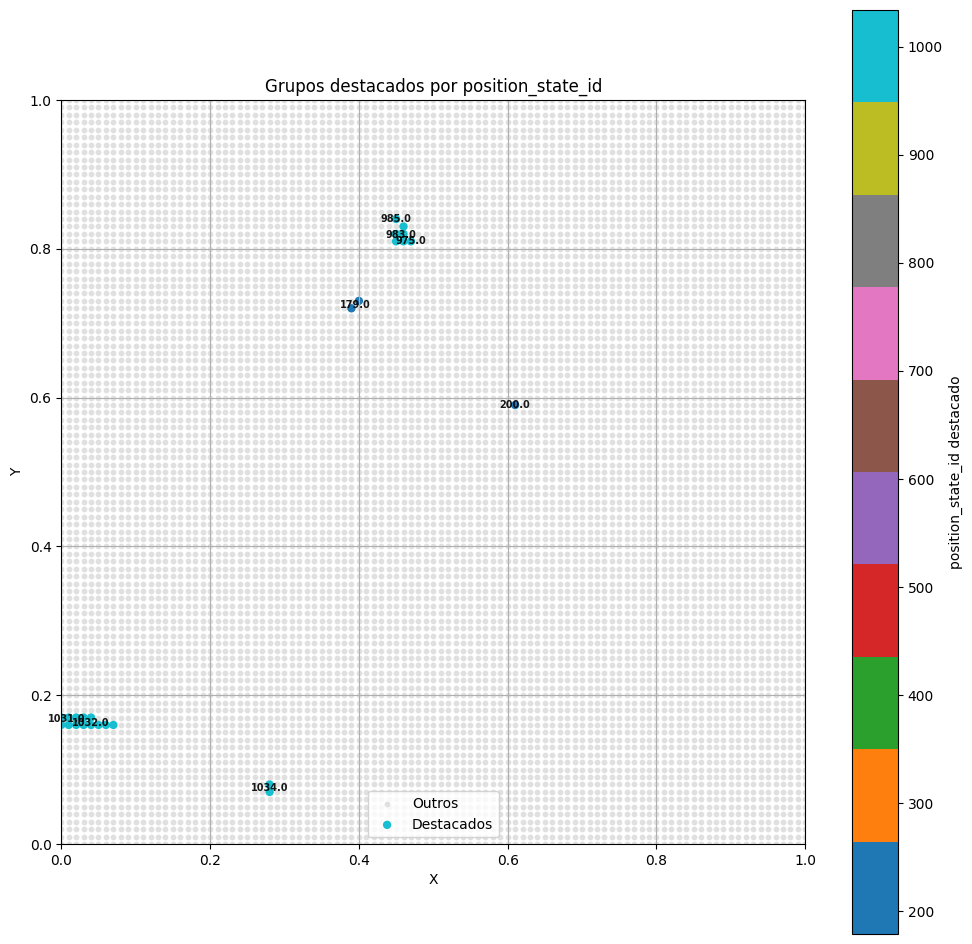

In [100]:
grupos_para_destacar = [200, 179, 985, 975, 983, 1031, 1032, 1034, 1031]
plot_position_states(apd, grupos_para_destacar)

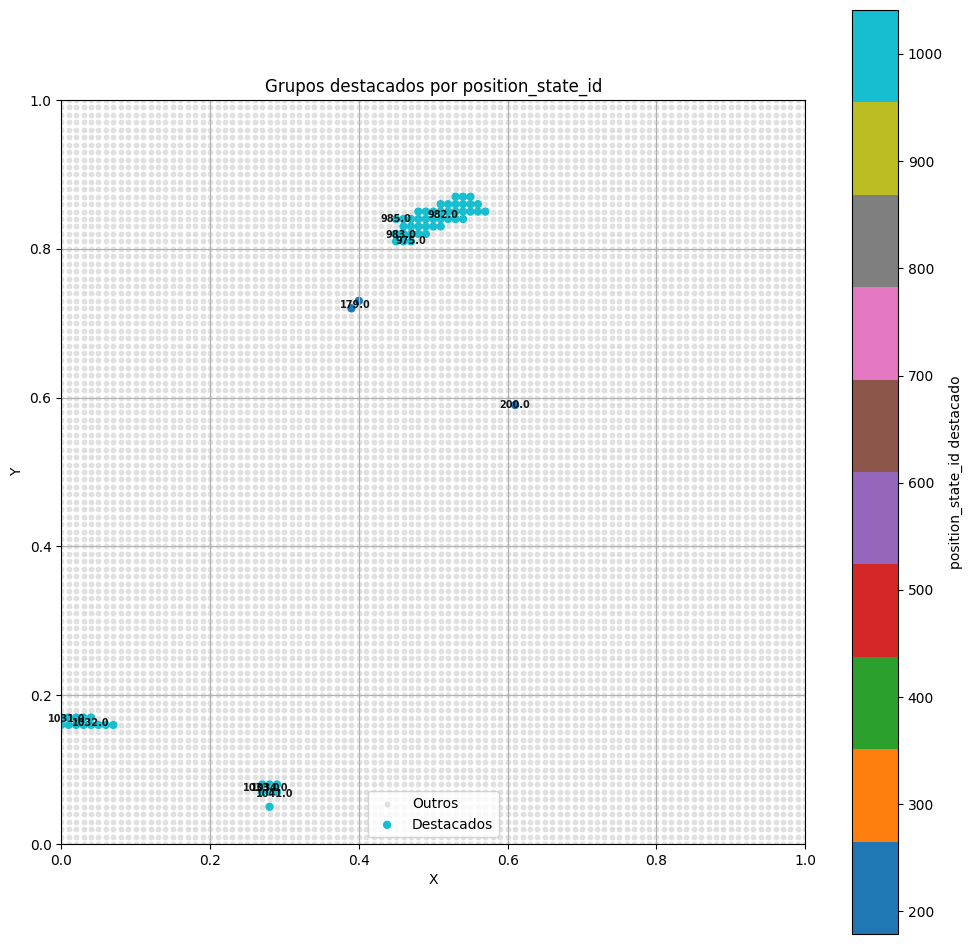

In [101]:
grupos_para_destacar = [200, 1747, 179, 983, 985, 983, 975, 982, 983, 1032, 1031, 1034, 1032, 1033, 1034, 1041, 1031]
plot_position_states(apd, grupos_para_destacar)

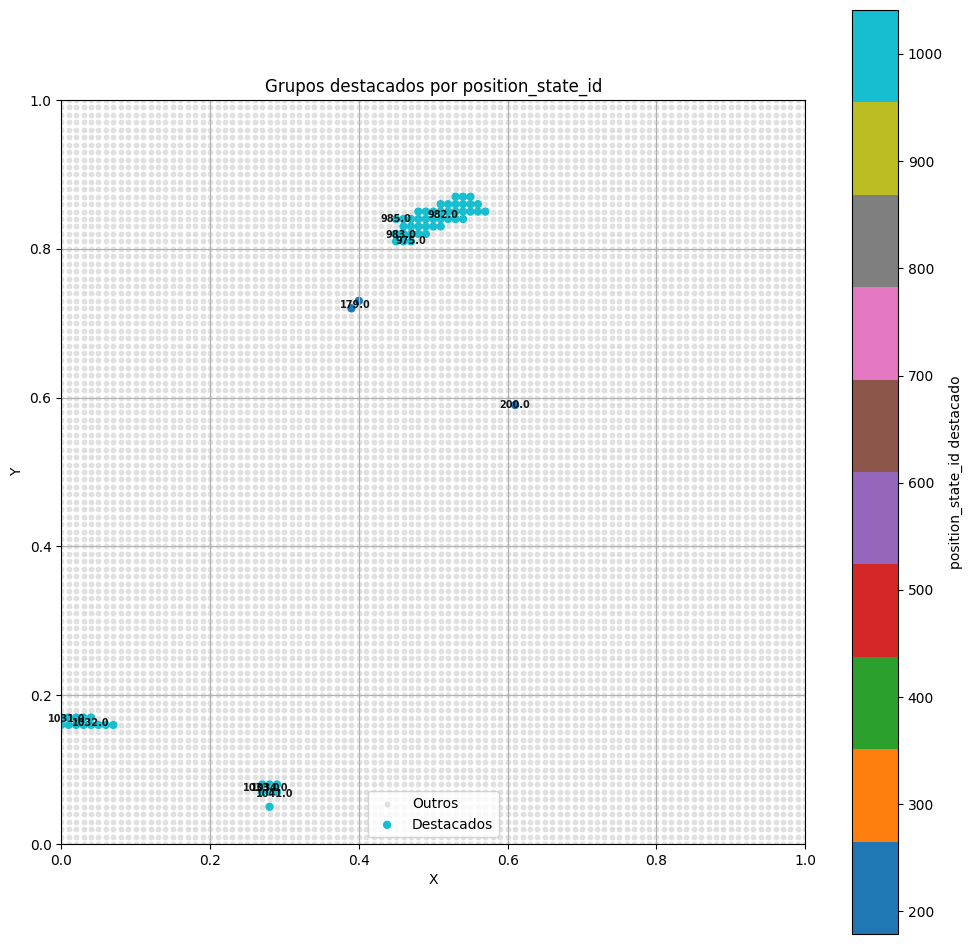

In [102]:
grupos_para_destacar = [200, 1747, 179, 983, 985, 983, 975, 982, 983, 1032, 1031, 1034, 1032, 1033, 1034, 1041, 1031]
plot_position_states(apd, grupos_para_destacar)